In [1]:
import numpy as np
import pandas as pd


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "c:\ProgramData\anaconda3\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "c:\ProgramData\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_loop.start()
  File "c:\ProgramData\anaconda3\Lib\site-pack

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: numpy.core.multiarray failed to import

In [27]:
df = pd.read_csv("..\\Data\\heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [28]:
df.rename(
    columns={
        'age': 'age',
        'sex': 'sex',
        'cp': 'chest_pain_type',
        'trestbps': 'resting_blood_pressure',
        'chol': 'cholesterol',
        'fbs': 'fasting_blood_sugar',
        'restecg': 'resting_ecg',
        'thalach': 'maximum_heart_rate',
        'exang': 'exercise_angina',
        'oldpeak': 'ST_depression',
        'slope': 'st_slope',
        'ca': 'major_vessels_count',
        'thal': 'thalassemia',
        'target': 'heart_disease'
    },
    inplace=True
)

In [29]:
df.corr()['heart_disease'].sort_values(ascending=False)

heart_disease             1.000000
chest_pain_type           0.434854
maximum_heart_rate        0.422895
st_slope                  0.345512
resting_ecg               0.134468
fasting_blood_sugar      -0.041164
cholesterol              -0.099966
resting_blood_pressure   -0.138772
age                      -0.229324
sex                      -0.279501
thalassemia              -0.337838
major_vessels_count      -0.382085
exercise_angina          -0.438029
ST_depression            -0.438441
Name: heart_disease, dtype: float64

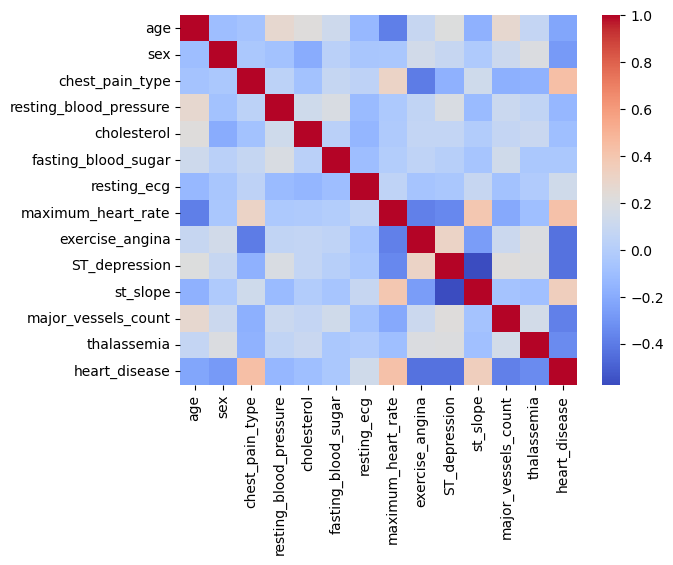

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df.corr(), annot=False, cmap='coolwarm')
plt.show()

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     1025 non-null   int64  
 1   sex                     1025 non-null   int64  
 2   chest_pain_type         1025 non-null   int64  
 3   resting_blood_pressure  1025 non-null   int64  
 4   cholesterol             1025 non-null   int64  
 5   fasting_blood_sugar     1025 non-null   int64  
 6   resting_ecg             1025 non-null   int64  
 7   maximum_heart_rate      1025 non-null   int64  
 8   exercise_angina         1025 non-null   int64  
 9   ST_depression           1025 non-null   float64
 10  st_slope                1025 non-null   int64  
 11  major_vessels_count     1025 non-null   int64  
 12  thalassemia             1025 non-null   int64  
 13  heart_disease           1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 1

In [32]:
df.shape

(1025, 14)

In [33]:
for i in df.columns:
    print(f"{i}: {df[i].nunique()} unique values")

age: 41 unique values
sex: 2 unique values
chest_pain_type: 4 unique values
resting_blood_pressure: 49 unique values
cholesterol: 152 unique values
fasting_blood_sugar: 2 unique values
resting_ecg: 3 unique values
maximum_heart_rate: 91 unique values
exercise_angina: 2 unique values
ST_depression: 40 unique values
st_slope: 3 unique values
major_vessels_count: 5 unique values
thalassemia: 4 unique values
heart_disease: 2 unique values


num_cols (standardScaler) -> age, resting_blood,pressure, cholesterol, maximum_heart_rate, ST_depression


cat_cols(OHE) -> sex, chest_pain_type, fasting_blood_sugar, resting_ecg, exercise_angina, st_slope, major_vessels_count, thalassemia, heart_disease (target)

              

In [34]:
df.describe()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,maximum_heart_rate,exercise_angina,ST_depression,st_slope,major_vessels_count,thalassemia,heart_disease
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


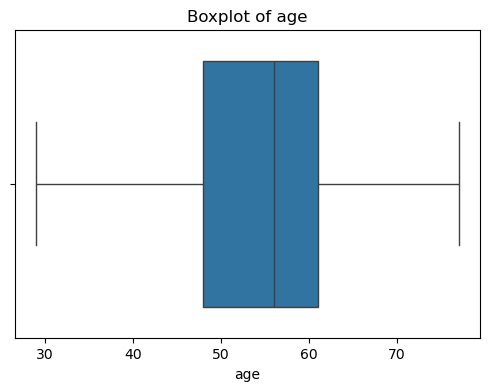

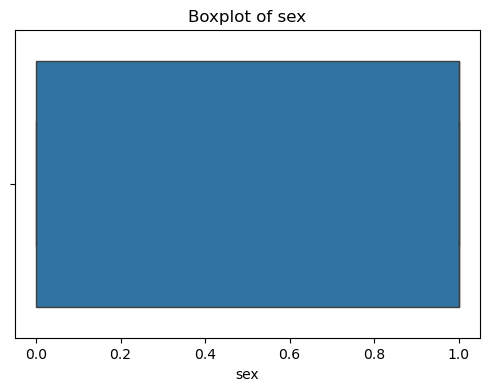

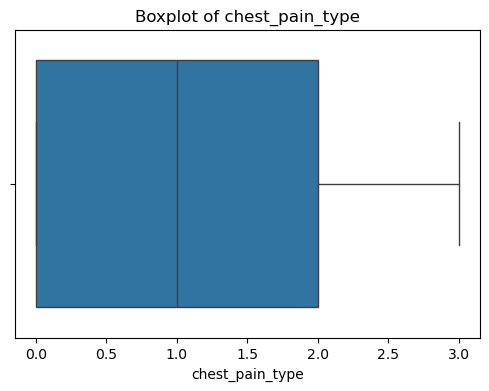

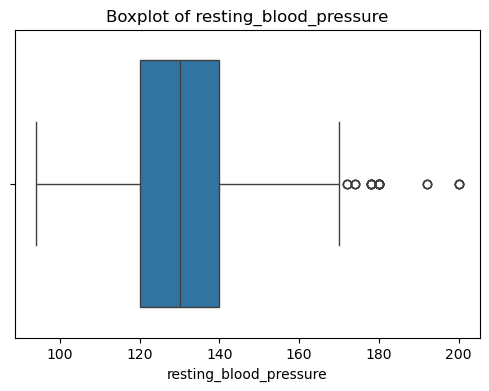

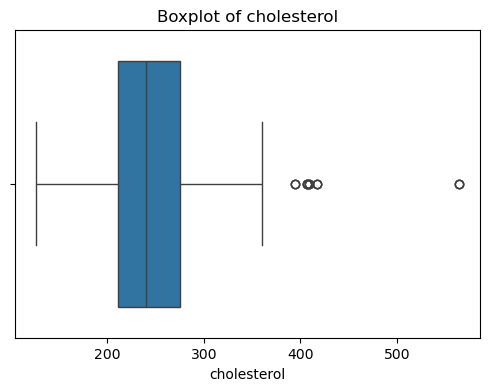

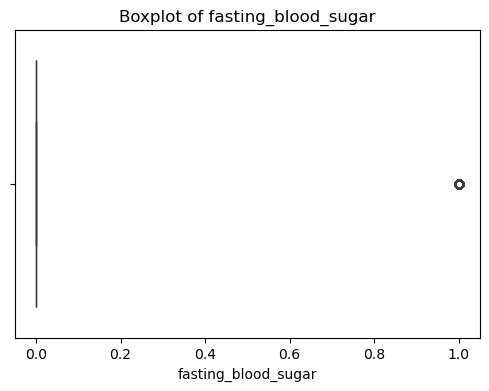

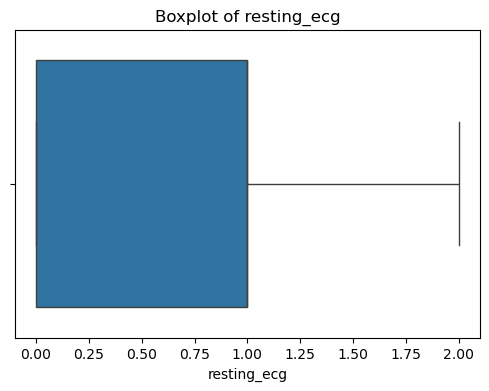

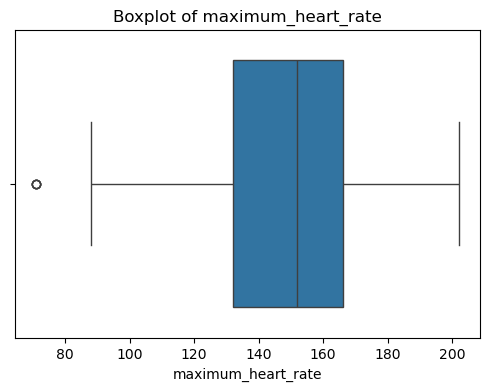

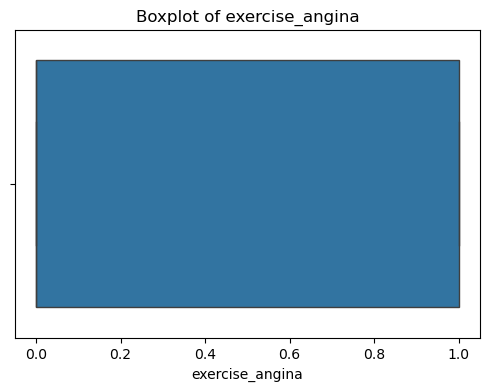

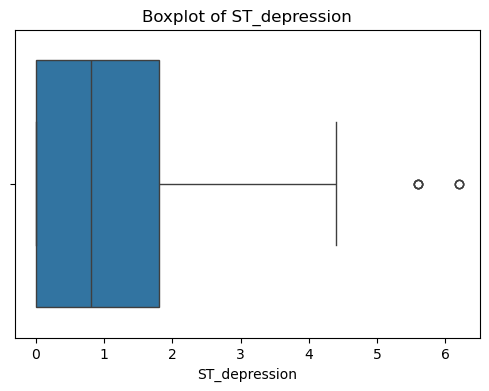

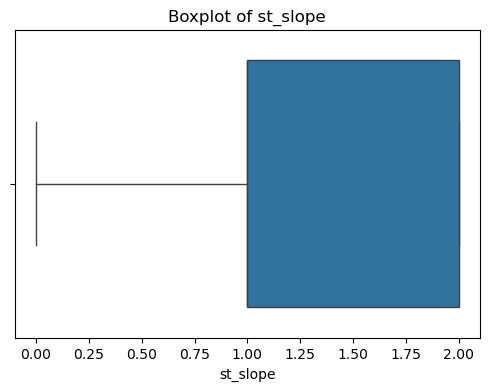

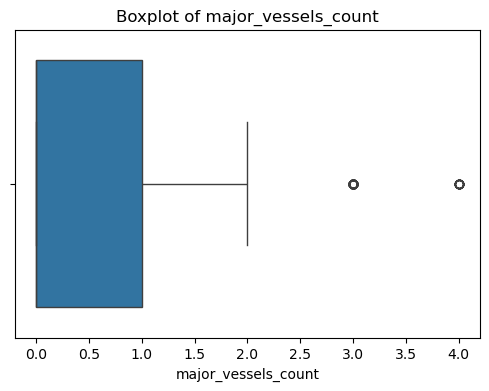

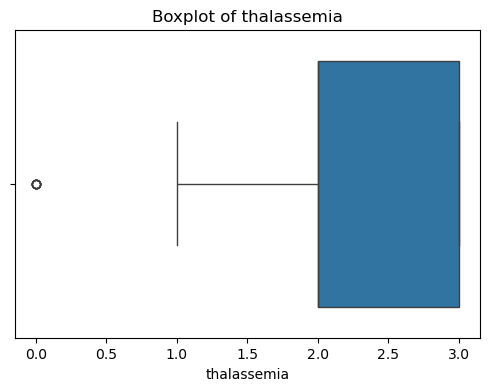

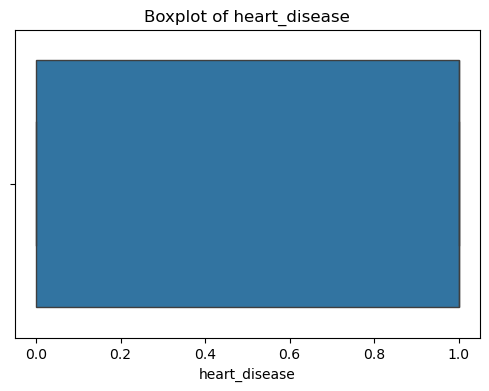

In [35]:
# checking for outliers using boxplots adjusting in three rows
for column in df.columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[column])
    plt.title(f'Boxplot of {column}')
    plt.show()

In [36]:
#  removing outliers using IQR method
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
df = df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]


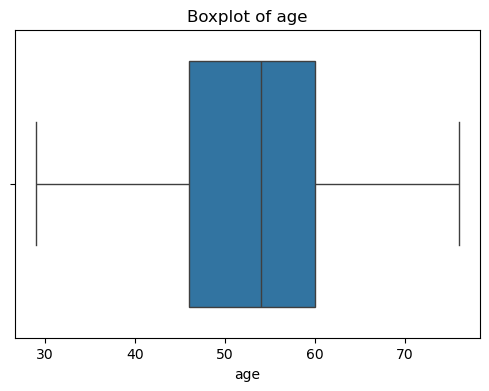

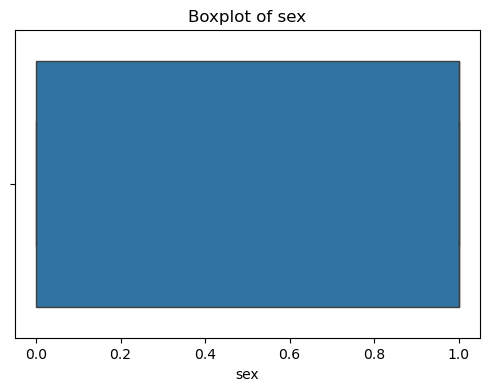

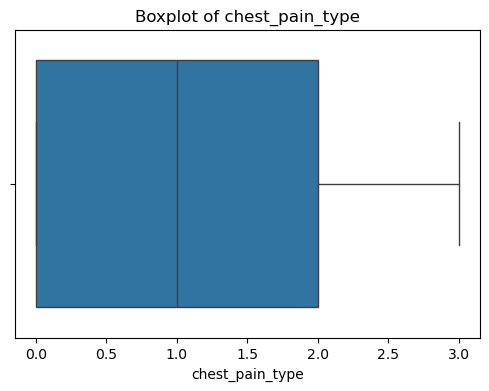

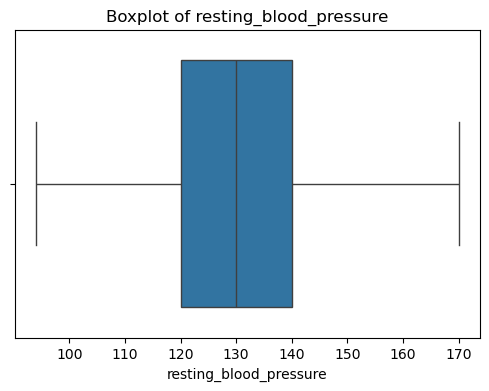

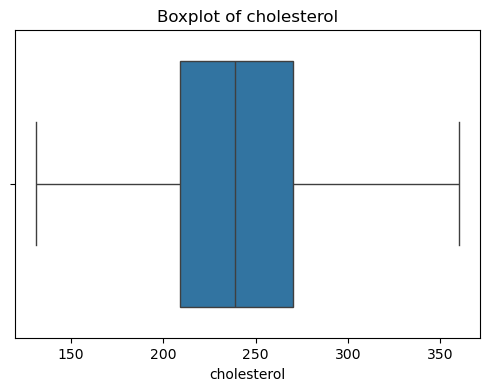

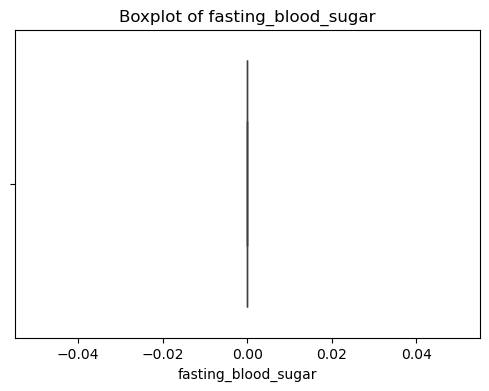

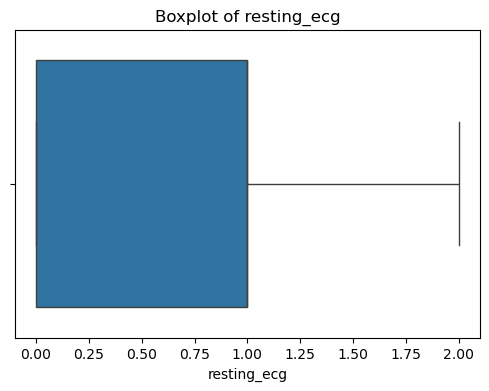

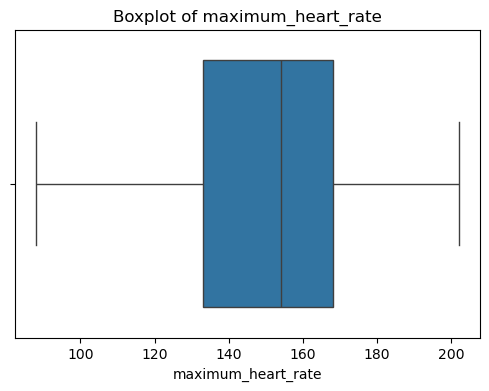

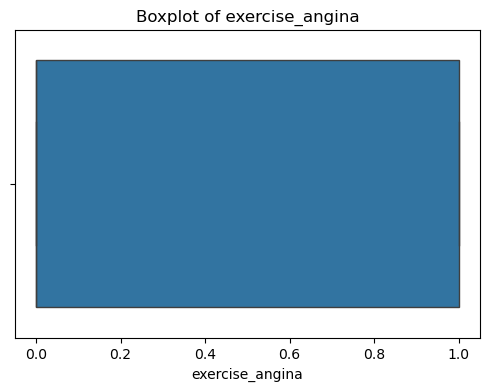

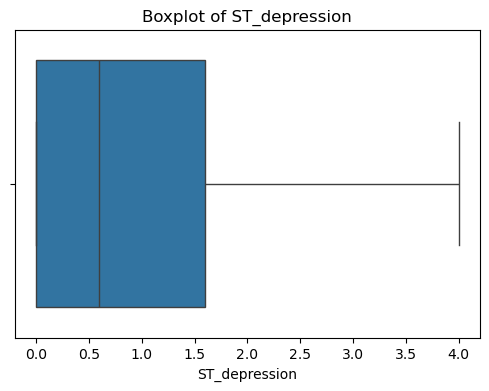

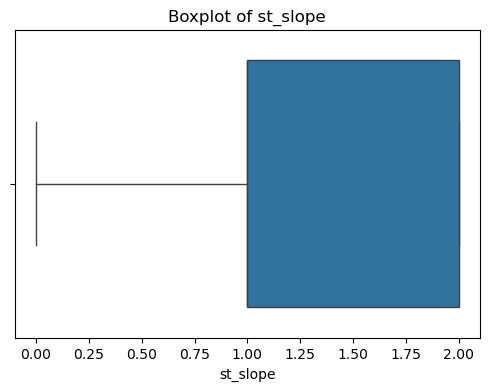

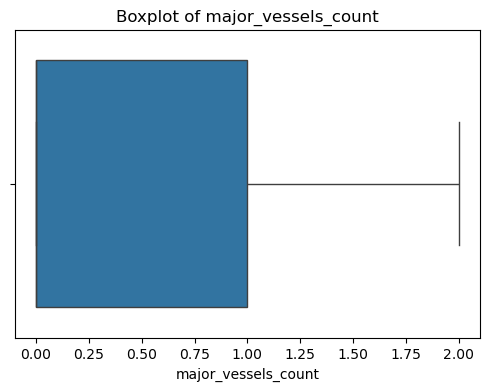

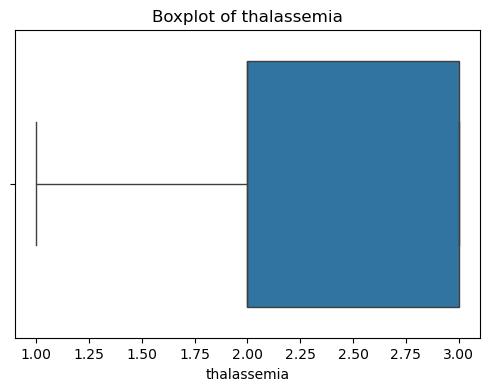

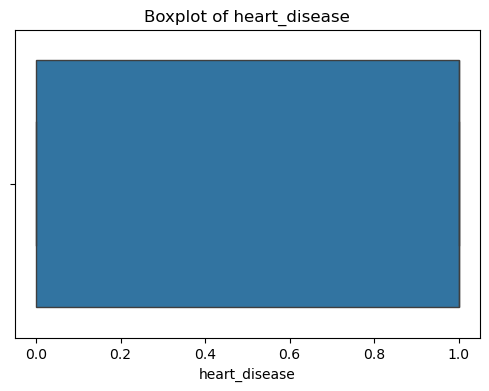

In [37]:
for column in df.columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[column])
    plt.title(f'Boxplot of {column}')
    plt.show()

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 769 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     769 non-null    int64  
 1   sex                     769 non-null    int64  
 2   chest_pain_type         769 non-null    int64  
 3   resting_blood_pressure  769 non-null    int64  
 4   cholesterol             769 non-null    int64  
 5   fasting_blood_sugar     769 non-null    int64  
 6   resting_ecg             769 non-null    int64  
 7   maximum_heart_rate      769 non-null    int64  
 8   exercise_angina         769 non-null    int64  
 9   ST_depression           769 non-null    float64
 10  st_slope                769 non-null    int64  
 11  major_vessels_count     769 non-null    int64  
 12  thalassemia             769 non-null    int64  
 13  heart_disease           769 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 90.1 KB

In [39]:
# checking the data skewness
for column in df.columns:
    skewness = df[column].skew()
    print(f'Skewness of {column}: {skewness}')

Skewness of age: -0.17737055107296645
Skewness of sex: -0.8324160451003928
Skewness of chest_pain_type: 0.5807054885411267
Skewness of resting_blood_pressure: 0.2762802175588966
Skewness of cholesterol: 0.26680451612203193
Skewness of fasting_blood_sugar: 0.0
Skewness of resting_ecg: -0.006654018594508058
Skewness of maximum_heart_rate: -0.48275536014743575
Skewness of exercise_angina: 0.7545992365496371
Skewness of ST_depression: 0.9442658065009976
Skewness of st_slope: -0.5032368025778574
Skewness of major_vessels_count: 1.0758015715498601
Skewness of thalassemia: -0.14324933784617003
Skewness of heart_disease: -0.19637613876437657


In [40]:
clean_df = df.copy()

In [41]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 769 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     769 non-null    int64  
 1   sex                     769 non-null    int64  
 2   chest_pain_type         769 non-null    int64  
 3   resting_blood_pressure  769 non-null    int64  
 4   cholesterol             769 non-null    int64  
 5   fasting_blood_sugar     769 non-null    int64  
 6   resting_ecg             769 non-null    int64  
 7   maximum_heart_rate      769 non-null    int64  
 8   exercise_angina         769 non-null    int64  
 9   ST_depression           769 non-null    float64
 10  st_slope                769 non-null    int64  
 11  major_vessels_count     769 non-null    int64  
 12  thalassemia             769 non-null    int64  
 13  heart_disease           769 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 90.1 KB

In [42]:
clean_df.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,maximum_heart_rate,exercise_angina,ST_depression,st_slope,major_vessels_count,thalassemia,heart_disease
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0


In [43]:
# download the cleaned dataset
clean_df.to_csv('..\\Data\\cleaned_heart_disease_data.csv', index=False)